# 10 — Softmax regression

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–09, especially 01 (indexing), 04 (cross-entropy, MLE = minimum cross-entropy), 06 (the training loop), 09 (logistic regression), and Problem 2 of the Chapter 1 problem set (stable log-sum-exp) |
| **You will learn** | Why $K$ separate binary classifiers are a poor multiclass model; the softmax function and its properties (shift invariance, temperature, the sigmoid as the case $K = 2$); the softmax regression model and its convex polygonal decision regions; categorical cross-entropy as maximum likelihood; numerically stable log-softmax and `F.cross_entropy`; the gradient $(P - Y)/N$; the initial-loss check $L \approx \ln K$ |
| **Estimated time** | About 3 hours, plus 1–2 hours for the exercises |
| **Compute** | CPU, well under a minute. No GPU section: these models are far too small for a GPU to help. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: cpu


In [2]:
import math

import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from torch import nn

from dlcourse.data import make_blobs, make_spirals
from dlcourse.plotting import COLORS, plot_dataset, plot_decision_boundary

## The motivating problem

Notebook 09 built a classifier for **two** classes: one logit $z$, one probability $\sigma(z)$, and binary cross-entropy. Real classification problems usually have more: ten digits, thousands of image categories, tens of thousands of words in a vocabulary. **How do we turn $K$ scores into one probability distribution over $K$ classes, and what loss trains it?**

The answer, **softmax regression** (also called *multinomial logistic regression*), is the output layer of nearly every classifier in this course, including the language models of later chapters. By the end of this notebook you will have derived it, made it numerically safe, computed its gradient by hand, trained it, and found the kind of data it cannot handle.

Notation, used for the whole of Chapter 2: data $X$ of shape `(N, D)` with one example per **row**; labels $\mathbf{y}$ of shape `(N,)`, integers in $\{0, \dots, K-1\}$; weights $W$ of shape `(K, D)` (the `(out, in)` layout of `nn.Linear`) and bias $\mathbf{b}$ of shape `(K,)`; logits $Z = XW^\top + \mathbf{b}$ of shape `(N, K)`; probabilities $P$ of shape `(N, K)`. Logs are natural logs.

## 1. Multiclass data, and a naive baseline

Our running dataset has $K = 4$ Gaussian blobs of 100 points each, with $D = 2$ features so we can draw everything. Three blobs sit on a horizontal line and the fourth sits above the middle one.

In [3]:
CENTERS = ((-3.0, 0.0), (0.0, 0.0), (3.0, 0.0), (0.0, 3.0))
X, y = make_blobs(n=100, centers=CENTERS, std=0.7, seed=0)  # X: (N, D) float32, y: (N,) int64
N, D = X.shape
K = len(CENTERS)
print(f"X: {tuple(X.shape)} {X.dtype}   y: {tuple(y.shape)} {y.dtype}   N = {N}, D = {D}, K = {K}")
print("examples per class:", torch.bincount(y).tolist())

X: (400, 2) torch.float32   y: (400,) torch.int64   N = 400, D = 2, K = 4
examples per class: [100, 100, 100, 100]


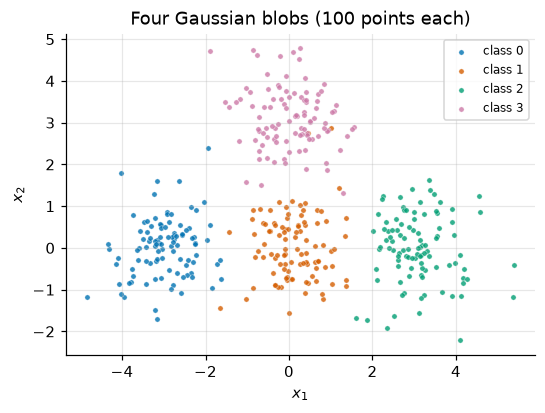

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
plot_dataset(X, y, ax=ax, title="Four Gaussian blobs (100 points each)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

The classes overlap a little at their edges (the standard deviation is 0.7 and neighbouring centers are 3 apart), so no classifier can be perfect, but a good one should be right almost everywhere.

### One-vs-rest: $K$ logistic regressions

We already know how to build a binary classifier. The obvious idea is **one-vs-rest**: train $K$ separate logistic regressions, where classifier $k$ answers "is this example class $k$ or not?". Its target for example $i$ is $Y_{ik} = 1$ if $y_i = k$ and 0 otherwise. The matrix $Y$ of shape `(N, K)` is the **one-hot** encoding of the labels: row $i$ is all zeros except a 1 in column $y_i$. `F.one_hot` builds it.

In [5]:
Y = F.one_hot(y, K).float()  # (N, K): Y[i, k] = 1 if y[i] == k else 0
print("first label:", y[0].item(), "  its one-hot row:", Y[0].tolist())
print("labels 100, 200, 300:", y[[100, 200, 300]].tolist(), "\n", Y[[100, 200, 300]])

first label: 0   its one-hot row: [1.0, 0.0, 0.0, 0.0]
labels 100, 200, 300: [1, 2, 3] 
 tensor([[0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 0., 1.]])


We can train all $K$ binary classifiers at once. Stack their weight vectors as the rows of $W$ `(K, D)` and their biases in $\mathbf{b}$ `(K,)`. Then column $k$ of $Z = XW^\top + \mathbf{b}$ holds the logits of classifier $k$, and the binary cross-entropy averaged over all $N \times K$ entries (`F.binary_cross_entropy_with_logits` from notebook 09) is a sum of $K$ independent losses: column $k$ of the loss depends only on row $k$ of $W$. Full-batch gradient descent, from zero:

In [6]:
W_ovr = torch.zeros(K, D, requires_grad=True)  # (K, D): one binary classifier per row
b_ovr = torch.zeros(K, requires_grad=True)     # (K,)
for step in range(2000):
    Z_ovr = X @ W_ovr.T + b_ovr                # (N, K): column k = logits of classifier k
    loss = F.binary_cross_entropy_with_logits(Z_ovr, Y)
    loss.backward()
    with torch.no_grad():
        W_ovr -= 0.5 * W_ovr.grad
        b_ovr -= 0.5 * b_ovr.grad
    W_ovr.grad.zero_()
    b_ovr.grad.zero_()

with torch.no_grad():
    P_ovr = torch.sigmoid(X @ W_ovr.T + b_ovr)  # (N, K): P_ovr[i, k] = "probability" that example i is class k
print(f"final average BCE: {loss.item():.4f}")
print("classifier weights (rows):\n", W_ovr.detach().round(decimals=3))
print("biases:", b_ovr.detach().round(decimals=3).tolist())

final average BCE: 0.1576
classifier weights (rows):
 tensor([[-3.2230, -0.7090],
        [ 0.0070, -0.5540],
        [ 3.2160, -0.7260],
        [-0.0210,  3.0940]])
biases: [-4.409999847412109, -0.8389999866485596, -4.88700008392334, -5.551000118255615]


Classifiers 0, 2 and 3 have large weights pointing towards their blobs. Classifier 1 — "middle blob versus the rest" — is weak: its weight vector is short and points *down*. No single straight line separates the middle blob from blobs on **both** sides of it, so the best this linear classifier can do is to say "no" almost everywhere. Let's look at what the four classifiers say together.

In [7]:
row_sums = P_ovr.sum(dim=1)                    # (N,)
claims = (P_ovr > 0.5).sum(dim=1)              # (N,): how many classifiers say "mine"
print(f"sum over k of P_ovr[i, k]: min {row_sums.min().item():.3f}, max {row_sums.max().item():.3f}")
print(f"largest P_ovr[i, 1] on a class-1 example: {P_ovr[y == 1, 1].max().item():.3f}")
for c in range(3):
    print(f"training points claimed by exactly {c} classifiers: {(claims == c).sum().item()}")
print(f"class-1 examples claimed by nobody: {((claims == 0) & (y == 1)).sum().item()} of 100")
print(f"accuracy of argmax_k P_ovr[i, k]: {(P_ovr.argmax(dim=1) == y).float().mean().item():.3f}")

sum over k of P_ovr[i, k]: min 0.272, max 1.657
largest P_ovr[i, 1] on a class-1 example: 0.507
training points claimed by exactly 0 classifiers: 97
training points claimed by exactly 1 classifiers: 294
training points claimed by exactly 2 classifiers: 9
class-1 examples claimed by nobody: 94 of 100
accuracy of argmax_k P_ovr[i, k]: 0.975


Three problems:

1. **The "probabilities" are not a distribution.** For each example the $K$ numbers should sum to 1; here the sums range from about 0.27 to 1.66.
2. **Some points are claimed by nobody.** The class-1 classifier gives its own examples a probability of at most about 0.51, so 97 training points are rejected by all four classifiers, among them 94 of the 100 middle-blob points.
3. **Some points are claimed by two classifiers** (9 training points here, and large areas of the plane, as the plot shows).

Taking the largest score, $\arg\max_k$ `P_ovr[i, k]`, still classifies 97.5% of the training points correctly here, because the *other* three classifiers are confident that middle points are not theirs. But the scores themselves mean little, and the classifier we would train for class 1 is useless on its own.

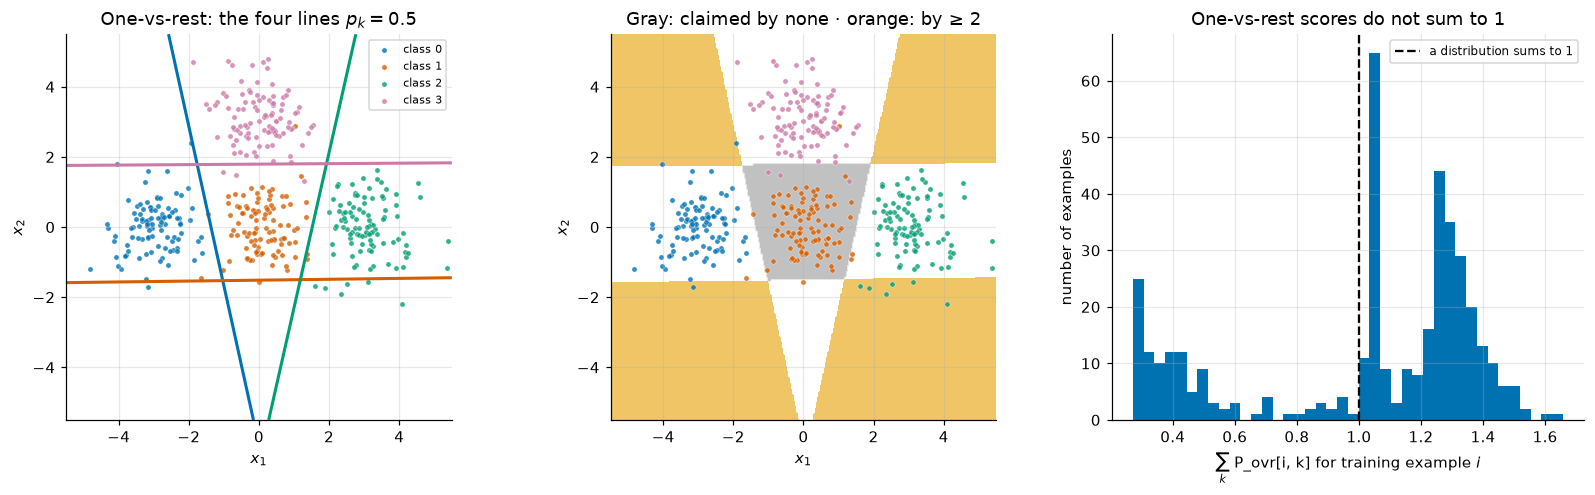

In [8]:
g = torch.linspace(-5.5, 5.5, 300)
G1, G2 = torch.meshgrid(g, g, indexing="xy")               # (300, 300) each
grid = torch.stack([G1.reshape(-1), G2.reshape(-1)], dim=1)  # (90000, 2)
with torch.no_grad():
    P_grid = torch.sigmoid(grid @ W_ovr.T + b_ovr)           # (90000, K)
claims_grid = (P_grid > 0.5).sum(dim=1).reshape(300, 300)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
ax = axes[0]
for k in range(K):
    ax.contour(G1, G2, P_grid[:, k].reshape(300, 300), levels=[0.5], colors=[COLORS[k]], linewidths=2)
plot_dataset(X, y, ax=ax, title="One-vs-rest: the four lines $p_k = 0.5$")
ax.set_xlim(-5.5, 5.5)
ax.set_ylim(-5.5, 5.5)
ax.legend(loc="upper right", fontsize=7)

ax = axes[1]
claim_cmap = ListedColormap(["#999999", "#ffffff", "#E69F00"])
ax.contourf(G1, G2, claims_grid.clamp(max=2), levels=[-0.5, 0.5, 1.5, 2.5], cmap=claim_cmap, alpha=0.6)
plot_dataset(X, y, ax=ax, title="Gray: claimed by none · orange: by ≥ 2")
ax.set_xlim(-5.5, 5.5)
ax.set_ylim(-5.5, 5.5)

ax = axes[2]
ax.hist(row_sums, bins=40, color=COLORS[0])
ax.axvline(1.0, color="k", ls="--", label="a distribution sums to 1")
ax.set_xlabel(r"$\sum_k$ P_ovr[i, k] for training example $i$")
ax.set_ylabel("number of examples")
ax.set_title("One-vs-rest scores do not sum to 1")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Left: the class-1 line (orange) lies *below* almost all the data — classifier 1 claims an empty strip at the bottom and gives up on its own blob. Middle: the whole middle blob sits in a gray "nobody's" region, and the corners are orange "contested" regions where two classifiers each claim the point. Right: the scores rarely sum to 1.

The root cause is that the $K$ classifiers are trained **independently**: nothing makes them compete for each example. The fix is to make one model output all $K$ probabilities **jointly**, so that raising one class's probability necessarily lowers the others.

## 2. Softmax: from $K$ logits to a probability distribution

Suppose a model produces $K$ real numbers $\mathbf{z} = (z_0, \dots, z_{K-1})$, called **logits** (scores; larger means "more likely"). We need $K$ probabilities: positive and summing to 1. Exponentiate to make every score positive, then divide by the total:

$$\operatorname{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=0}^{K-1} e^{z_j}}, \qquad k = 0, \dots, K-1.$$

The name: it is a "soft" version of the arg-max. The largest logit gets the largest share, but every class gets some.

A small example by hand: $\mathbf{z} = (1, 2, 3)$ gives $e^{\mathbf{z}} \approx (2.718, 7.389, 20.086)$, total $\approx 30.19$, so $\operatorname{softmax}(\mathbf{z}) \approx (0.090, 0.245, 0.665)$.

In [9]:
def softmax_naive(z):
    """Softmax along the last dimension, straight from the definition. z: (..., K) -> (..., K)."""
    e = torch.exp(z)
    return e / e.sum(dim=-1, keepdim=True)


z = torch.tensor([1.0, 2.0, 3.0])
p = softmax_naive(z)
print("exp(z)       =", torch.exp(z).tolist())
print("softmax(z)   =", p.tolist())
print("torch.softmax =", torch.softmax(z, dim=0).tolist())
print("sum =", p.sum().item())

exp(z)       = [2.7182817459106445, 7.389056205749512, 20.08553695678711]
softmax(z)   = [0.09003057330846786, 0.2447284758090973, 0.6652409434318542]
torch.softmax = [0.09003057330846786, 0.2447284758090973, 0.6652409434318542]
sum = 1.0


`dim=-1` (the last dimension) makes the same function work for one logit vector of shape `(K,)` and for a batch of shape `(N, K)`, where it normalizes **each row**. `keepdim=True` keeps the sum's shape `(N, 1)` so that it broadcasts against `(N, K)` row by row (notebook 01). In PyTorch, `torch.softmax(Z, dim=1)` on a batch `(N, K)` does the same; the dimension must always be the **class** dimension.

### Properties, with proofs

1. **Positive:** $e^{z_k} > 0$, and so is the sum.
2. **Sums to 1:** $\sum_k e^{z_k} / \sum_j e^{z_j} = 1$.
3. **Shift invariance:** adding the same constant $c$ to every logit changes nothing. Proof in one line: $\dfrac{e^{z_k + c}}{\sum_j e^{z_j + c}} = \dfrac{e^c\, e^{z_k}}{e^c \sum_j e^{z_j}} = \dfrac{e^{z_k}}{\sum_j e^{z_j}}.$ So only **differences** between logits matter.
4. **Order-preserving:** $z_j > z_k \iff p_j > p_k$, because $e^t$ is strictly increasing and both share the same denominator. In particular $\arg\max_k p_k = \arg\max_k z_k$: to *predict* a class we never need to compute the softmax at all.

Numerically, on a batch of random logits:

In [10]:
gen = torch.Generator().manual_seed(0)
Z_rand = 3 * torch.randn(1000, 5, generator=gen)             # (1000, 5): 1000 logit vectors, K = 5
P_rand = softmax_naive(Z_rand)                               # (1000, 5)
shift = 10 * torch.randn(1000, 1, generator=gen)             # (1000, 1): a different constant per row
print("all positive:            ", bool((P_rand > 0).all()))
print("max |row sum - 1|:       ", (P_rand.sum(dim=1) - 1).abs().max().item())
print("max change after shift:  ", (softmax_naive(Z_rand + shift) - P_rand).abs().max().item())
print("argmax unchanged:        ", bool((P_rand.argmax(dim=1) == Z_rand.argmax(dim=1)).all()))
print("order of each row kept:  ", bool((P_rand.argsort(dim=1) == Z_rand.argsort(dim=1)).all()))

all positive:             True
max |row sum - 1|:        2.384185791015625e-07
max change after shift:   3.5762786865234375e-07
argmax unchanged:         True
order of each row kept:   True


The row sums equal 1 and the shift changes the probabilities only by `float32` rounding (about $10^{-7}$).

### Temperature: how peaked is the distribution?

Shifting logits does nothing, but **scaling** them matters. Divide the logits by a **temperature** $T > 0$, $\mathbf{p}(T) = \operatorname{softmax}(\mathbf{z}/T)$:

- **$T \to 0$: the arg-max.** Let $m$ be the index of the (unique) largest logit. For $k \ne m$, $p_k / p_m = e^{(z_k - z_m)/T} \to 0$ because $z_k - z_m < 0$. Since the $p$'s sum to 1, $p_m \to 1$: a one-hot vector.
- **$T \to \infty$: uniform.** $\mathbf{z}/T \to \mathbf{0}$, and $\operatorname{softmax}(\mathbf{0})_k = e^0 / (K e^0) = 1/K$.

$T = 1$ is plain softmax. Multiplying the logits by $c$ is the same as $T = 1/c$; Exercise 1 uses this.

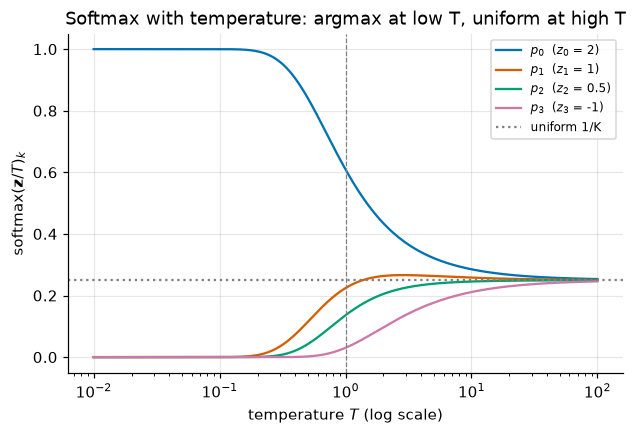

T = 0.01: [1.0, 0.0, 0.0, 0.0]    T = 100: [0.2533999979496002, 0.250900000333786, 0.24969999492168427, 0.2460000067949295]


In [11]:
z_T = torch.tensor([2.0, 1.0, 0.5, -1.0])                  # (K,) with K = 4
Ts = torch.logspace(-2, 2, 400)                            # (400,) temperatures from 0.01 to 100
P_T = torch.softmax(z_T / Ts[:, None], dim=1)              # (400, 4): one distribution per temperature
fig, ax = plt.subplots(figsize=(6.5, 4))
for k in range(4):
    ax.semilogx(Ts, P_T[:, k], color=COLORS[k], label=f"$p_{k}$  ($z_{k}$ = {z_T[k].item():g})")
ax.axhline(1 / 4, color="gray", ls=":", label="uniform 1/K")
ax.axvline(1.0, color="gray", ls="--", lw=0.8)
ax.set_xlabel("temperature $T$ (log scale)")
ax.set_ylabel(r"softmax$(\mathbf{z}/T)_k$")
ax.set_title("Softmax with temperature: argmax at low T, uniform at high T")
ax.legend(fontsize=8)
plt.show()
print("T = 0.01:", P_T[0].round(decimals=4).tolist(), "   T = 100:", P_T[-1].round(decimals=4).tolist())

Left of the plot, the class with the largest logit takes all the probability; right of the plot, every class gets $1/4$. In between, the curves never cross: at every temperature the order of the probabilities is the order of the logits (property 4).

### $K = 2$: softmax is the sigmoid of notebook 09

With two classes and logits $(z_0, z_1)$, divide the numerator and denominator by $e^{z_1}$:

$$\operatorname{softmax}(z_0, z_1)_1 = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0).$$

So a two-class softmax model *is* logistic regression, with logit $z = z_1 - z_0$. If $z_k = \mathbf{w}_k \cdot \mathbf{x} + b_k$, then $z = (\mathbf{w}_1 - \mathbf{w}_0)\cdot\mathbf{x} + (b_1 - b_0)$: the weight vector of notebook 09 is the difference $\mathbf{w}_1 - \mathbf{w}_0$. Everything in notebook 09 is the special case $K = 2$ of this notebook.

In [12]:
Z2 = 4 * torch.randn(1000, 2, generator=gen)               # (1000, 2) random two-class logits
p1_softmax = torch.softmax(Z2, dim=1)[:, 1]                # (1000,)
p1_sigmoid = torch.sigmoid(Z2[:, 1] - Z2[:, 0])            # (1000,)
print(f"max |softmax(z)_1 - sigmoid(z_1 - z_0)| = {(p1_softmax - p1_sigmoid).abs().max().item():.2e}")

max |softmax(z)_1 - sigmoid(z_1 - z_0)| = 5.96e-08


### Overparameterization

Shift invariance has a consequence for models. If every logit is $z_k = \mathbf{w}_k \cdot \mathbf{x} + b_k$, adding the same vector $\mathbf{c}$ to every $\mathbf{w}_k$ and the same number $d$ to every $b_k$ adds $\mathbf{c}\cdot\mathbf{x} + d$ to every logit — the same shift for all classes — so the probabilities are unchanged for **every** input. The model has $K(D+1)$ parameters but only $(K-1)(D+1)$ of them matter (for $K = 2$: $2(D+1)$ parameters, but only the difference counts, as above). We will meet the consequence again in Section 6: the loss has flat directions.

In [13]:
W_test = torch.randn(K, D, generator=gen)                  # (K, D)
b_test = torch.randn(K, generator=gen)                     # (K,)
c_vec, d_val = torch.tensor([5.0, -3.0]), 7.0              # the same shift for every class
P_a = torch.softmax(X @ W_test.T + b_test, dim=1)                       # (N, K)
P_b = torch.softmax(X @ (W_test + c_vec).T + (b_test + d_val), dim=1)  # W_test + c_vec adds c_vec to every row
print(f"max |P_a - P_b| over the whole dataset: {(P_a - P_b).abs().max().item():.2e}")

max |P_a - P_b| over the whole dataset: 5.96e-07


### Checkpoint 2.1

By hand first: compute the softmax of $\mathbf{z} = (0, \ln 2, \ln 3)$. (Hint for the hand calculation: $e^{\ln a} = a$.) Store it in `p_hand` (shape `(3,)`), computed from the definition with `torch.exp` (not `torch.softmax`).

<details>
<summary><b>💡 Hint</b></summary>

$e^{\mathbf{z}} = (1, 2, 3)$ and the sum is 6, so the answer is $(1/6, 2/6, 3/6)$. In code: `e = torch.exp(z_hand)`, then `e / e.sum()`.

</details>

In [ ]:
z_hand = torch.tensor([0.0, math.log(2), math.log(3)])
# YOUR CODE HERE
raise NotImplementedError
print("p_hand =", p_hand)

In [ ]:
check_shape(p_hand, (3,), "p_hand")
check_close(p_hand, torch.tensor([1 / 6, 2 / 6, 3 / 6]), "p_hand")
passed("Checkpoint 2.1")

### Checkpoint 2.2

Two quick verifications of the properties above, using `z_hand`:

1. `p_shifted`: the softmax of `z_hand + 100` (use `torch.softmax(..., dim=0)`). It should equal `p_hand`.
2. `p1_two_class`: for the two logits $(z_0, z_1) = (0.5, 2.0)$ in `z_two`, the probability of class 1 computed with `torch.sigmoid` (not softmax).

<details>
<summary><b>💡 Hint</b></summary>

`torch.softmax(z_hand + 100, dim=0)`. For the second part, $p_1 = \sigma(z_1 - z_0)$: `torch.sigmoid(z_two[1] - z_two[0])`.

</details>

In [ ]:
z_two = torch.tensor([0.5, 2.0])
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_close(p_shifted, torch.tensor([1 / 6, 2 / 6, 3 / 6]), "p_shifted")
check_close(p1_two_class, torch.softmax(z_two, dim=0)[1], "p1_two_class")
passed("Checkpoint 2.2")

## 3. The model: softmax regression

Give each class its own linear score of the input, then apply softmax to each row:

$$Z = XW^\top + \mathbf{b}, \qquad P = \operatorname{softmax}(Z) \text{ along dim 1}.$$

Shapes: $X$ is `(N, D)`, $W^\top$ is `(D, K)`, so $XW^\top$ is `(N, K)`, and the bias `(K,)` broadcasts across the rows. Entry $Z_{ik} = \mathbf{w}_k \cdot \mathbf{x}_i + b_k$, where $\mathbf{w}_k$ is row $k$ of $W$. This is exactly `nn.Linear(D, K)` followed by a softmax. The model's probabilistic claim is

$$p(y_i = k \mid \mathbf{x}_i) = P_{ik},$$

a categorical distribution over the $K$ classes for each input, whose parameters depend on the input.

### Decision regions

The predicted class is $\hat y_i = \arg\max_k P_{ik} = \arg\max_k Z_{ik}$ (property 4). Class $j$ beats class $k$ at $\mathbf{x}$ when $z_j(\mathbf{x}) > z_k(\mathbf{x})$, that is

$$(\mathbf{w}_j - \mathbf{w}_k)\cdot\mathbf{x} + (b_j - b_k) > 0.$$

That is one side of a straight line (a hyperplane when $D > 2$) — the same kind of boundary as notebooks 07–09. The region where class $k$ wins is the set of points where it beats each of the other $K - 1$ classes: an **intersection of $K-1$ half-planes**. An intersection of half-planes is convex (if two points satisfy every inequality, so does every point on the segment between them, since each inequality is linear). So **softmax regression divides the input space into at most $K$ convex polygonal regions** (some possibly empty or unbounded), with straight-line boundaries.

### A hand-built example: nearest center

Before any training, here is a softmax-regression classifier we can write down. "Assign $\mathbf{x}$ to the nearest blob center $\mathbf{c}_k$" sounds nonlinear, but expanding the squared distance,

$$\|\mathbf{x} - \mathbf{c}_k\|^2 = \|\mathbf{x}\|^2 - 2\,\mathbf{c}_k\cdot\mathbf{x} + \|\mathbf{c}_k\|^2.$$

The term $\|\mathbf{x}\|^2$ is the same for every $k$, so minimizing the distance is the same as maximizing $\mathbf{c}_k \cdot \mathbf{x} - \tfrac12\|\mathbf{c}_k\|^2$: a linear score with $\mathbf{w}_k = \mathbf{c}_k$ and $b_k = -\tfrac12\|\mathbf{c}_k\|^2$.

In [18]:
W_nc = torch.tensor(CENTERS)                 # (K, D): row k is center k
b_nc = -0.5 * (W_nc**2).sum(dim=1)           # (K,)
print("W_nc =\n", W_nc, "\nb_nc =", b_nc.tolist())


def predict_nc(points):
    """Nearest-center classifier as a linear model. points: (P, D) -> (P,) labels."""
    return (points @ W_nc.T + b_nc).argmax(dim=1)

W_nc =
 tensor([[-3.,  0.],
        [ 0.,  0.],
        [ 3.,  0.],
        [ 0.,  3.]]) 
b_nc = [-4.5, -0.0, -4.5, -4.5]


Its boundary between classes 0 and 1: $\mathbf{w}_0 - \mathbf{w}_1 = (-3, 0)$ and $b_0 - b_1 = -4.5$, so the line is $-3x_1 - 4.5 = 0$, i.e. $x_1 = -1.5$ — the perpendicular bisector of the two centers. Between classes 0 and 3: $(-3, -3)\cdot\mathbf{x} + 0 = 0$, i.e. $x_2 = -x_1$. We draw both lines over the regions.

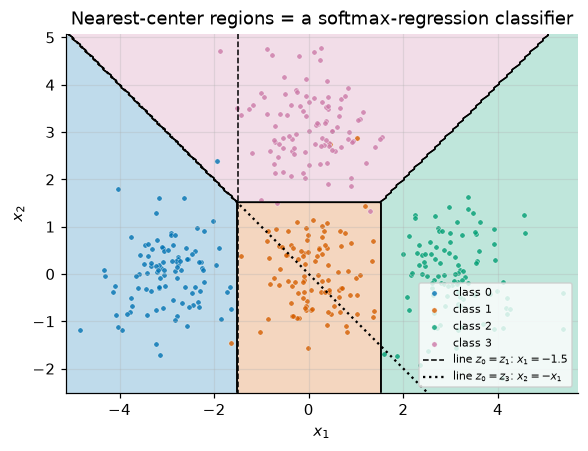

In [19]:
fig, ax = plt.subplots(figsize=(6, 5))
plot_decision_boundary(predict_nc, X, y, ax=ax, title="Nearest-center regions = a softmax-regression classifier")
t_line = torch.linspace(-6, 6, 2)
ax.plot([-1.5, -1.5], [-6, 6], "--", color="k", lw=1, label="line $z_0 = z_1$: $x_1 = -1.5$")
ax.plot(t_line, -t_line, ":", color="k", lw=1.5, label="line $z_0 = z_3$: $x_2 = -x_1$")
ax.legend(loc="lower right", fontsize=7)
plt.show()

The four regions are convex: class 1 is an unbounded strip with three sides, and the others are unbounded wedges. Each dashed or dotted line is a boundary only along the stretch where those two classes are the top two; elsewhere (for example the dashed line above $x_2 = 1.5$, inside class 3's region) a third class beats both, and the line plays no role. The middle blob — impossible for one-vs-rest — gets its own region without difficulty, because classes compete *with each other* rather than each against "the rest".

### Checkpoint 3.1

For the nearest-center weights `W_nc`, `b_nc`, compute the logits `Z_nc` for the whole dataset (shape `(N, K)`), the predicted labels `pred_nc` (shape `(N,)`), and the training accuracy `acc_nc` (a float between 0 and 1). Do not call `predict_nc`.

<details>
<summary><b>💡 Hint</b></summary>

`Z_nc = X @ W_nc.T + b_nc`, `pred_nc = Z_nc.argmax(dim=1)`, and the accuracy is the mean of the boolean tensor `pred_nc == y` after `.float()`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print(f"nearest-center training accuracy: {acc_nc:.4f}")

In [ ]:
check_shape(Z_nc, (N, K), "Z_nc")
check_shape(pred_nc, (N,), "pred_nc")
check(torch.equal(pred_nc, predict_nc(X)), "pred_nc should be the arg-max of each row of Z_nc")
check_close(acc_nc, (predict_nc(X) == y).float().mean().item(), "acc_nc")
passed("Checkpoint 3.1")

The hand-built classifier is already right on about 98% of the training points. But it only gives labels; it does not tell us how to *learn* $W$ and $\mathbf{b}$ from data, nor how confident to be. For that we need a loss.

## 4. The loss: categorical cross-entropy

The model says $p(y_i = k \mid \mathbf{x}_i) = P_{ik}$. Assuming the examples are independent, the likelihood of the observed labels is $\prod_i P_{i, y_i}$: for each example, the probability the model gave to the class that actually occurred. As in notebooks 04, 06 and 09, we maximize it by minimizing the average **negative log-likelihood**:

$$L(W, \mathbf{b}) = -\frac{1}{N}\sum_{i=1}^{N} \log P_{i, y_i}.$$

With the one-hot matrix $Y$ the same sum reads

$$L = -\frac{1}{N}\sum_{i=1}^{N}\sum_{k=0}^{K-1} Y_{ik}\log P_{ik},$$

because in row $i$ only the term $k = y_i$ has $Y_{ik} \ne 0$. The inner sum, $-\sum_k Y_{ik}\log P_{ik}$, is the **cross-entropy** $H(\mathbf{Y}_i, \mathbf{P}_i)$ of notebook 04 between the "true" distribution of example $i$ (all mass on its label) and the model's distribution. Notebook 04 showed that maximum likelihood is minimum cross-entropy; that is why this loss is called **categorical cross-entropy**. For $K = 2$ it is exactly the binary cross-entropy of notebook 09 (substitute $P_{i1} = \sigma(z)$, $P_{i0} = 1 - \sigma(z)$).

Each term is $-\log$ (probability of the correct class): 0 when the model puts probability 1 on the right class, $\ln 2 \approx 0.69$ when it puts $1/2$ there, and $+\infty$ as that probability goes to 0.

### Picking the true-class probabilities

The one-hot form multiplies $N \times K$ numbers, almost all by zero. The direct way is to *index*: we need entry $(i, y_i)$ of $P$ for every row $i$. That is the pattern from notebook 01: `P[torch.arange(N), y]` pairs row index `i` with column index `y[i]`.

In [22]:
Z_demo = torch.tensor([[2.0, 1.0, 0.1],
                       [0.5, 2.5, 0.3],
                       [1.2, 0.2, 3.0]])               # (3, 3): 3 examples, K = 3
y_demo = torch.tensor([0, 2, 2])                       # (3,): example 1 is labelled 2 but scored low
P_demo = torch.softmax(Z_demo, dim=1)                  # (3, 3)
p_true = P_demo[torch.arange(3), y_demo]               # (3,): P[0, 0], P[1, 2], P[2, 2]
print("P_demo =\n", P_demo.round(decimals=4))
print("true-class probabilities:", p_true.round(decimals=4).tolist())
print("per-example losses -log p:", (-p_true.log()).round(decimals=4).tolist())

loss_index = -p_true.log().mean()
loss_onehot = -(F.one_hot(y_demo, 3) * P_demo.log()).sum(dim=1).mean()
print(f"loss by indexing: {loss_index.item():.6f}   one-hot form: {loss_onehot.item():.6f}   "
      f"F.cross_entropy(Z_demo, y_demo): {F.cross_entropy(Z_demo, y_demo).item():.6f}")

P_demo =
 tensor([[0.6590, 0.2424, 0.0986],
        [0.1086, 0.8025, 0.0889],
        [0.1348, 0.0496, 0.8156]])
true-class probabilities: [0.6589999794960022, 0.08889999985694885, 0.8155999779701233]
per-example losses -log p: [0.4169999957084656, 2.4200000762939453, 0.2037999927997589]
loss by indexing: 1.013642   one-hot form: 1.013642   F.cross_entropy(Z_demo, y_demo): 1.013642


Example 1 is the expensive one: its correct class got probability 0.09, which costs $-\ln 0.09 \approx 2.4$, more than the other two examples together. The three computations agree. Note that `F.cross_entropy` was given the **logits** `Z_demo`, not the probabilities — Section 5 explains why.

### Checkpoint 4.1

By hand first. Three examples, $K = 3$, with predicted probabilities `P_small` and labels `y_small` below. Compute `p_true_small` (the probability of each example's correct class, shape `(3,)`, by indexing) and `loss_small` (the cross-entropy, a 0-d tensor). Every probability is a power of $1/2$, so the answer is a multiple of $\ln 2$.

<details>
<summary><b>💡 Hint</b></summary>

The true-class probabilities are $1/2, 1/4, 1/8$, so the losses are $\ln 2$, $2\ln 2$, $3\ln 2$ and their mean is $2\ln 2$. In code: `P_small[torch.arange(3), y_small]`, then `-....log().mean()`.

</details>

In [ ]:
P_small = torch.tensor([[0.5, 0.25, 0.25],
                        [0.25, 0.25, 0.5],
                        [0.125, 0.125, 0.75]])  # (3, 3), each row sums to 1
y_small = torch.tensor([0, 0, 1])
# YOUR CODE HERE
raise NotImplementedError
print("p_true_small =", p_true_small, "  loss_small =", loss_small)

In [ ]:
check_shape(p_true_small, (3,), "p_true_small")
check_close(p_true_small, torch.tensor([0.5, 0.25, 0.125]), "p_true_small")
check_close(loss_small, 2 * math.log(2), "loss_small")
passed("Checkpoint 4.1")

### The initial-loss check: $L \approx \ln K$

Here is a habit we will use for every classifier in this course. If all $K$ logits of an example are equal, softmax gives every class probability $1/K$, and the loss of that example is $-\log(1/K) = \ln K$. A freshly initialized model with **small** weights produces logits that are all close to zero, hence nearly equal, so

$$L_{\text{initial}} \approx \ln K.$$

For $K = 4$, $\ln 4 \approx 1.386$; for the 10 digit classes $\ln 10 \approx 2.303$; for a vocabulary of 50,000 words, $\ln 50{,}000 \approx 10.8$. A very different initial loss is a sign that something is wrong before training even starts — Exercise 4 investigates what. With exactly zero weights the equality is exact:

In [25]:
W0, b0 = torch.zeros(K, D), torch.zeros(K)
print(f"loss with zero weights: {F.cross_entropy(X @ W0.T + b0, y).item():.6f}    ln K = {math.log(K):.6f}")

torch.manual_seed(0)
default_model = nn.Linear(D, K)
with torch.no_grad():
    print(f"loss of nn.Linear with its default initialization: {F.cross_entropy(default_model(X), y).item():.4f}")
    print("its logit range on our data:", round(default_model(X).min().item(), 2), "to", round(default_model(X).max().item(), 2))

loss with zero weights: 1.386295    ln K = 1.386294
loss of nn.Linear with its default initialization: 1.5824
its logit range on our data: -3.11 to 3.62


PyTorch's default initialization draws weights uniformly from $[-1/\sqrt{D}, 1/\sqrt{D}]$, about $\pm 0.71$ here. Our inputs reach magnitudes around 4, so the logits spread over several units and the initial loss (about 1.58) sits somewhat above $\ln 4$. That is "close" in the sense that matters: the warning signs are losses of 5 or 50, not 1.6. Chapter 3 (notebook 18) explains how to choose initial scales deliberately.

### Checkpoint 4.2

Create `model_small = nn.Linear(D, K)`, then (inside `torch.no_grad()`) overwrite its weight with draws from $\mathcal{N}(0, 0.01^2)$ (`.normal_(0, 0.01)`) and its bias with zeros. Compute its loss on `X`, `y` with `F.cross_entropy` and store it in `loss_init` (a float). The check compares it with $\ln K$.

<details>
<summary><b>💡 Hint</b></summary>

`model_small.weight.normal_(0, 0.01)` and `model_small.bias.zero_()` inside `with torch.no_grad():`. Then `F.cross_entropy(model_small(X), y).item()`.

</details>

In [ ]:
torch.manual_seed(1)
# YOUR CODE HERE
raise NotImplementedError
print(f"initial loss {loss_init:.4f}   ln K = {math.log(K):.4f}")

In [ ]:
check(isinstance(loss_init, float), "loss_init should be a Python float (use .item())")
check(model_small.weight.abs().max().item() < 0.1, "the weights should be small draws from N(0, 0.01²)")
check(abs(loss_init - math.log(K)) < 0.05, f"initial loss {loss_init:.4f} should be within 0.05 of ln K = {math.log(K):.4f}")
passed("Checkpoint 4.2")

## 5. Numerical stability

Logits are unbounded, and a confident network easily produces logits in the hundreds. The direct formula then fails:

In [28]:
z_big = torch.tensor([1000.0, 1001.0, 1002.0])
z_neg = torch.tensor([-1000.0, -1001.0, -1002.0])
print("exp(z_big)            =", torch.exp(z_big))
print("softmax_naive(z_big)  =", softmax_naive(z_big))
print("softmax_naive(z_neg)  =", softmax_naive(z_neg))

exp(z_big)            = tensor([inf, inf, inf])
softmax_naive(z_big)  = tensor([nan, nan, nan])
softmax_naive(z_neg)  = tensor([nan, nan, nan])


For `z_big` every exponential overflows to `inf` and $\infty/\infty$ is `nan`. For `z_neg` every exponential underflows to 0 and $0/0$ is `nan`. Yet both answers are perfectly ordinary: by shift invariance both equal $\operatorname{softmax}(0, -1, -2) \approx (0.665, 0.245, 0.090)$ — the example from Section 2 in reverse order.

### Stable softmax: subtract the max

Shift invariance (Section 2) says we may subtract any constant from the logits. Subtracting $m = \max_k z_k$ makes the largest exponent $e^0 = 1$: nothing overflows, and the denominator is at least 1, so nothing divides by zero. This is the same max-shift you used for log-sum-exp in Chapter 1, Problem 2.

In [29]:
def softmax_stable(z):
    """Softmax along the last dimension, safe for large logits. z: (..., K) -> (..., K)."""
    e = torch.exp(z - z.max(dim=-1, keepdim=True).values)  # largest entry of each row becomes exp(0) = 1
    return e / e.sum(dim=-1, keepdim=True)


print("softmax_stable(z_big) =", softmax_stable(z_big))
print("softmax_stable(z_neg) =", softmax_stable(z_neg))
print("max |softmax_stable - torch.softmax| on random logits:", (softmax_stable(Z_rand) - torch.softmax(Z_rand, dim=1)).abs().max().item())

softmax_stable(z_big) = tensor([0.0900, 0.2447, 0.6652])
softmax_stable(z_neg) = tensor([0.6652, 0.2447, 0.0900])
max |softmax_stable - torch.softmax| on random logits: 1.1920928955078125e-07


### The log of a tiny probability: log-softmax

The loss needs $\log P_{i, y_i}$, and a stable softmax followed by a `log` is still not enough. If the correct class has a logit 200 below the largest, its probability $e^{-200} \approx 10^{-87}$ underflows to 0 in `float32` (smallest positive value about $10^{-45}$), and the log becomes $-\infty$:

In [30]:
z_far = torch.tensor([0.0, -200.0])
print("softmax_stable(z_far)          =", softmax_stable(z_far))
print("log(softmax_stable(z_far))     =", torch.log(softmax_stable(z_far)))
print("F.log_softmax(z_far, dim=0)    =", F.log_softmax(z_far, dim=0))

softmax_stable(z_far)          = tensor([1., 0.])
log(softmax_stable(z_far))     = tensor([0., -inf])
F.log_softmax(z_far, dim=0)    = tensor([   0., -200.])


A model this wrong should get a large but **finite** loss of about 200, with a useful gradient; $-\infty$ would turn the loss into `inf` and the gradients into `nan`. The fix is to never form the probability: take the log analytically first,

$$\log \operatorname{softmax}(\mathbf{z})_k = z_k - \log\sum_j e^{z_j} = z_k - \operatorname{lse}(\mathbf{z}),$$

and compute the log-sum-exp stably with the max-shift, $\operatorname{lse}(\mathbf{z}) = m + \log\sum_j e^{z_j - m}$ (Chapter 1, Problem 2). Every quantity stays in a moderate range: $z_k - m \le 0$, and the sum lies between 1 and $K$. This is the **log-softmax**, `F.log_softmax`.

### Checkpoint 5.1

Write `log_softmax_stable(Z)` for a batch `Z` of shape `(N, K)`, returning shape `(N, K)`, using the max-shift and **without** `torch.logsumexp`, `torch.softmax`, or `F.log_softmax`. The check compares it with `F.log_softmax` on logits of size up to 1000.

<details>
<summary><b>💡 Hint</b></summary>

`m = Z.max(dim=1, keepdim=True).values` (shape `(N, 1)`), `shifted = Z - m`, and then `shifted - torch.log(torch.exp(shifted).sum(dim=1, keepdim=True))`. The two $m$'s cancel: $z_k - (m + \log\sum_j e^{z_j - m}) = (z_k - m) - \log\sum_j e^{z_j - m}$.

</details>

In [ ]:
def log_softmax_stable(Z):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
Z_check = torch.stack([z_big, z_neg, torch.tensor([0.0, -200.0, 5.0]), torch.tensor([1.0, 2.0, 3.0])])  # (4, 3)
out = log_softmax_stable(Z_check)
check_shape(out, (4, 3), "log_softmax_stable(Z_check)")
check(bool(torch.isfinite(out).all()), f"log_softmax_stable returned non-finite values:\n{out}")
check_close(out, F.log_softmax(Z_check, dim=1), "log_softmax_stable(Z_check)", atol=1e-5)
check_close(log_softmax_stable(Z_rand), F.log_softmax(Z_rand, dim=1), "log_softmax_stable(Z_rand)", atol=1e-5)
passed("Checkpoint 5.1")

### PyTorch's functions: `log_softmax`, `nll_loss`, `cross_entropy`

- `F.log_softmax(Z, dim=1)`: stable log-probabilities, shape `(N, K)`.
- `F.nll_loss(logP, y)`: given **log-probabilities** `(N, K)` and integer labels `(N,)`, returns $-\frac1N\sum_i \texttt{logP}[i, y_i]$. It just indexes and averages; it applies no softmax and no log.
- `F.cross_entropy(Z, y)`: given **logits** `(N, K)` and integer labels `(N,)`, computes `F.nll_loss(F.log_softmax(Z, dim=1), y)` in one stable step. `nn.CrossEntropyLoss()` is the same thing as a module.

We define our own reference implementation of the full loss for later sections, and compare all of them on logits as large as 1000, together with the naive formula:

In [33]:
def cross_entropy_ref(Z, y):
    """Mean categorical cross-entropy from logits Z (N, K) and integer labels y (N,)."""
    m = Z.max(dim=1, keepdim=True).values
    log_P = Z - m - torch.log(torch.exp(Z - m).sum(dim=1, keepdim=True))  # (N, K) stable log-softmax
    return -log_P[torch.arange(len(y)), y].mean()


gen = torch.Generator().manual_seed(1)
y_cmp = torch.randint(0, 5, (1000,), generator=gen)           # (1000,) labels for Z_rand (K = 5)
for scale in [1.0, 1000.0]:
    Zs = scale * Z_rand
    naive = -torch.log(softmax_naive(Zs)[torch.arange(1000), y_cmp]).mean()
    print(f"logits × {scale:6g}:  naive {naive.item():12.4f}   ours {cross_entropy_ref(Zs, y_cmp).item():12.4f}   "
          f"nll_loss(log_softmax) {F.nll_loss(F.log_softmax(Zs, dim=1), y_cmp).item():12.4f}   "
          f"F.cross_entropy {F.cross_entropy(Zs, y_cmp).item():12.4f}")

logits ×      1:  naive       3.7208   ours       3.7208   nll_loss(log_softmax)       3.7208   F.cross_entropy       3.7208
logits ×   1000:  naive          nan   ours    3398.0818   nll_loss(log_softmax)    3398.0818   F.cross_entropy    3398.0818


With ordinary logits all four agree. Multiplied by 1000, the naive formula returns `nan` while the stable versions agree on a large, finite loss.

### What `F.cross_entropy` expects

The target must be **integer class indices** of dtype `int64` and shape `(N,)`. The error messages for the common mistakes:

In [34]:
logits_demo = X[:5] @ W_nc.T + b_nc                     # (5, K) logits
for name, target in [("float labels, shape (N,)", y[:5].float()),
                     ("one-hot as int64, shape (N, K)", F.one_hot(y[:5], K))]:
    try:
        F.cross_entropy(logits_demo, target)
    except RuntimeError as err:
        print(f"{name:32s} -> RuntimeError: {err}")
print("integer labels:                   ", F.cross_entropy(logits_demo, y[:5]).item())
print("one-hot as float32, shape (N, K): ", F.cross_entropy(logits_demo, F.one_hot(y[:5], K).float()).item())

float labels, shape (N,)         -> RuntimeError: expected target dtype to be Long or Byte, but got Float
one-hot as int64, shape (N, K)   -> RuntimeError: Expected floating point type for target with class probabilities, got Long
integer labels:                    0.02036730945110321
one-hot as float32, shape (N, K):  0.02036730758845806


A **float** target of shape `(N, K)` is accepted. It is interpreted as a *probability distribution* per example (useful for label smoothing in notebook 23), and for one-hot rows it gives the same loss as integer labels. Integer labels are the normal case.

### The double-softmax bug

The input must be **logits**. Passing probabilities produces no error at all, just a wrong number:

In [35]:
P_nc = torch.softmax(logits_demo, dim=1)
print(f"F.cross_entropy(logits, y)          = {F.cross_entropy(logits_demo, y[:5]).item():.4f}   (correct)")
print(f"F.cross_entropy(softmax(logits), y) = {F.cross_entropy(P_nc, y[:5]).item():.4f}   (silently wrong)")

F.cross_entropy(logits, y)          = 0.0204   (correct)
F.cross_entropy(softmax(logits), y) = 0.7578   (silently wrong)


`F.cross_entropy` applies its own softmax, so the model's probabilities get a **second** softmax. Its inputs now lie in $[0, 1]$, and a softmax of numbers in $[0, 1]$ can never be confident. Even a perfect prediction, the one-hot vector, gives probability $e^1/(e^1 + (K-1)e^0)$ to the correct class. So the double-softmax loss is at least

$$-\log\frac{e}{e + K - 1} = \log\left(1 + \frac{K-1}{e}\right),$$

about 0.744 for $K = 4$, however good the model. The loss curve plateaus well above zero and the gradients are squashed. Exercise 3 shows what this does to training.

In [36]:
perfect = 50 * F.one_hot(y, K).float()                 # (N, K): extremely confident, always right
print(f"double-softmax loss of a perfect classifier: {F.cross_entropy(torch.softmax(perfect, dim=1), y).item():.4f}")
print(f"log(1 + (K-1)/e) = {math.log(1 + (K - 1) / math.e):.4f}")
print(f"correct loss of the same classifier:         {F.cross_entropy(perfect, y).item():.2e}")

double-softmax loss of a perfect classifier: 0.7437
log(1 + (K-1)/e) = 0.7437
correct loss of the same classifier:         0.00e+00


## 6. The gradient

To train with gradient descent we need $\partial L / \partial W$ and $\partial L / \partial \mathbf{b}$. As in notebook 06, we go in two steps: first the gradient with respect to the logits $Z$, then the chain rule through $Z = XW^\top + \mathbf{b}$.

### With respect to the logits

Take one example with logits $\mathbf{z}$ (shape `(K,)`), label $y$, and loss $\ell = -\log p_y$. Using log-softmax from Section 5,

$$\ell = -z_y + \operatorname{lse}(\mathbf{z}).$$

Differentiate with respect to $z_k$. The first term gives $-1$ if $k = y$ and 0 otherwise, i.e. $-Y_k$ with $\mathbf{Y}$ the one-hot vector. For the second, Chapter 1 Problem 2 found $\partial\,\operatorname{lse}/\partial z_k = e^{z_k}/\sum_j e^{z_j} = p_k$. So

$$\frac{\partial \ell}{\partial z_k} = p_k - Y_k, \qquad \nabla_{\mathbf{z}}\,\ell = \mathbf{p} - \mathbf{Y}.$$

"Predicted distribution minus target distribution" — the same clean form as $\hat p - y$ in notebook 09. The correct class is pushed up by $1 - p_y$ (a lot if the model was unsure, little if it was already confident), and every other class is pushed down by its own probability $p_k$. The gradient components always sum to zero, $\sum_k (p_k - Y_k) = 1 - 1 = 0$, consistent with shift invariance: moving all logits together changes nothing, so the gradient has no component along $(1, \dots, 1)$.

For the batch loss $L = \frac1N\sum_i \ell_i$, the logits of example $i$ appear only in $\ell_i$, so

$$\frac{\partial L}{\partial Z} = \frac{1}{N}(P - Y) \quad \text{(shape } (N, K)).$$

### The same result through the Jacobian of softmax

A second route checks the first. Differentiating $p_j = e^{z_j}/S$ with $S = \sum_k e^{z_k}$ by the quotient rule: $\partial p_j/\partial z_k = (e^{z_j}[j = k]\,S - e^{z_j} e^{z_k})/S^2 = p_j([j=k] - p_k)$. As a matrix,

$$J = \frac{\partial \mathbf{p}}{\partial \mathbf{z}} = \operatorname{diag}(\mathbf{p}) - \mathbf{p}\mathbf{p}^\top \quad (K \times K).$$

Then $\partial(-\log p_y)/\partial z_k = -\frac{1}{p_y}\,p_y([y = k] - p_k) = p_k - [y = k]$, the same answer. We verify $J$ with `torch.autograd.functional.jacobian` in `float64`:

In [37]:
z64 = torch.tensor([1.0, 2.0, 0.5, -1.0], dtype=torch.float64)
p64 = torch.softmax(z64, dim=0)
J_formula = torch.diag(p64) - torch.outer(p64, p64)                           # (K, K)
J_autograd = torch.autograd.functional.jacobian(lambda v: torch.softmax(v, dim=0), z64)
print("J (formula) =\n", J_formula.round(decimals=4))
print(f"max |formula - autograd| = {(J_formula - J_autograd).abs().max().item():.1e}")
print("row sums of J:", J_formula.sum(dim=1).round(decimals=12).tolist())

J (formula) =
 tensor([[ 0.1739, -0.1366, -0.0305, -0.0068],
        [-0.1366,  0.2380, -0.0829, -0.0185],
        [-0.0305, -0.0829,  0.1175, -0.0041],
        [-0.0068, -0.0185, -0.0041,  0.0294]], dtype=torch.float64)
max |formula - autograd| = 2.8e-17
row sums of J: [-0.0, -0.0, -0.0, -0.0]


The rows of $J$ sum to zero: increasing one logit raises its own probability exactly as much as it lowers all the others in total, so the probabilities keep summing to 1.

### With respect to the weights and bias

$Z_{ik} = \sum_d X_{id} W_{kd} + b_k$, so $\partial Z_{ik}/\partial W_{kd} = X_{id}$ and $\partial Z_{ik}/\partial b_k = 1$. Writing $G = \frac1N(P - Y)$ for the gradient with respect to $Z$, the chain rule sums over all the logits that each parameter touches:

$$\frac{\partial L}{\partial W_{kd}} = \sum_i G_{ik} X_{id} \;\Rightarrow\; \nabla_W L = G^\top X = \frac{1}{N}(P - Y)^\top X, \qquad \nabla_{\mathbf{b}} L = \sum_i G_{i,:} = \frac1N \sum_i (P - Y)_{i,:}.$$

Shapes: $G^\top$ is `(K, N)`, $X$ is `(N, D)`, so $\nabla_W L$ is `(K, D)`, the shape of $W$, as a gradient must be. Compare notebook 06, where $\nabla_{\mathbf{w}} L = \frac2N X^\top(\hat{\mathbf y} - \mathbf y)$: the same "error times input" structure. We check against autograd and central finite differences in `float64`:

In [38]:
def softmax_regression_grads(W, b, X, y):
    """Manual gradient of the mean cross-entropy. W: (K, D), b: (K,), X: (N, D), y: (N,) -> (dW (K, D), db (K,))."""
    n, k = X.shape[0], W.shape[0]
    P = softmax_stable(X @ W.T + b)                   # (N, K)
    G = (P - F.one_hot(y, k).to(X.dtype)) / n         # (N, K) = dL/dZ
    return G.T @ X, G.sum(dim=0)


X64 = X.double()
gen = torch.Generator().manual_seed(2)
W_t = torch.randn(K, D, dtype=torch.float64, generator=gen, requires_grad=True)
b_t = torch.randn(K, dtype=torch.float64, generator=gen, requires_grad=True)
cross_entropy_ref(X64 @ W_t.T + b_t, y).backward()
dW, db = softmax_regression_grads(W_t.detach(), b_t.detach(), X64, y)
print("manual dW =\n", dW.round(decimals=6), "\nautograd  =\n", W_t.grad.round(decimals=6))
print(f"max |manual - autograd|: dW {(dW - W_t.grad).abs().max().item():.1e}, db {(db - b_t.grad).abs().max().item():.1e}")
check_close(dW, W_t.grad, "dW vs autograd", rtol=1e-10, atol=1e-12)
check_close(db, b_t.grad, "db vs autograd", rtol=1e-10, atol=1e-12)

h = 1e-6
L_at = lambda W_, b_: cross_entropy_ref(X64 @ W_.T + b_, y).item()
fd_W = torch.zeros(K, D, dtype=torch.float64)
with torch.no_grad():
    for k in range(K):
        for d in range(D):
            E = torch.zeros(K, D, dtype=torch.float64)
            E[k, d] = h
            fd_W[k, d] = (L_at(W_t + E, b_t) - L_at(W_t - E, b_t)) / (2 * h)
print(f"max |manual dW - finite differences| = {(dW - fd_W).abs().max().item():.1e}")
check_close(dW, fd_W, "dW vs finite differences", rtol=1e-6, atol=1e-8)
passed("The gradient (P - Y)ᵀX / N matches autograd and finite differences")

manual dW =
 tensor([[ 0.6801,  0.0209],
        [-0.4428, -0.0437],
        [-0.1584, -0.0026],
        [-0.0789,  0.0254]], dtype=torch.float64) 
autograd  =
 tensor([[ 0.6801,  0.0209],
        [-0.4428, -0.0437],
        [-0.1584, -0.0026],
        [-0.0789,  0.0254]], dtype=torch.float64)
max |manual - autograd|: dW 1.1e-16, db 2.8e-17
max |manual dW - finite differences| = 1.5e-10
✅ The gradient (P - Y)ᵀX / N matches autograd and finite differences passed


Manual gradient and autograd agree to about $10^{-16}$ (rounding), and finite differences agree to about $10^{-10}$, the accuracy of a central difference with $h = 10^{-6}$ in `float64`.

### Convexity, and the flat directions

The second derivative of $\ell$ with respect to $\mathbf{z}$ is the derivative of $\mathbf{p} - \mathbf{Y}$, which is the Jacobian $J = \operatorname{diag}(\mathbf{p}) - \mathbf{p}\mathbf{p}^\top$ above. For any vector $\mathbf{v}$,

$$\mathbf{v}^\top J \mathbf{v} = \sum_k p_k v_k^2 - \Big(\sum_k p_k v_k\Big)^2 \ge 0,$$

because it is the variance of $v_k$ when $k$ is drawn with probabilities $p_k$. So $\ell$ is a **convex** function of $\mathbf{z}$, and since $\mathbf{z}$ is an affine function of $(W, \mathbf{b})$, the loss is convex in the parameters, by the same argument as notebook 09: gradient descent has no bad local minima to get stuck in. The variance is zero exactly when all $v_k$ are equal: $\mathbf{v} = (1, \dots, 1)$ is a flat direction — shift invariance again.

In parameter space, the flat directions are the overparameterization of Section 2: adding $\mathbf{c}$ to every $\mathbf{w}_k$ and $d$ to every $b_k$ leaves $L$ unchanged, which gives $D + 1 = 3$ flat directions here. Numerically, the Hessian of $L$ with respect to all $K(D+1) = 12$ parameters should have 3 zero eigenvalues and 9 positive ones:

In [39]:
def loss_flat(theta):
    """Mean cross-entropy as a function of all parameters flattened into one vector (K*D + K,)."""
    W_ = theta[: K * D].reshape(K, D)
    return cross_entropy_ref(X64 @ W_.T + theta[K * D:], y)


theta_t = torch.cat([W_t.detach().reshape(-1), b_t.detach()])         # (12,)
H = torch.autograd.functional.hessian(loss_flat, theta_t)              # (12, 12)
print("Hessian eigenvalues:", [f"{v:.2e}" for v in torch.linalg.eigvalsh(H).tolist()])

Hessian eigenvalues: ['-4.24e-17', '5.97e-17', '1.36e-16', '1.64e-02', '3.53e-02', '4.94e-02', '1.17e-01', '1.36e-01', '3.27e-01', '4.15e-01', '6.50e-01', '9.47e-01']


Three eigenvalues are zero up to `float64` rounding ($\sim 10^{-16}$; the tiny negative one is rounding too), and the other nine are clearly positive. The loss is convex but not *strictly* convex: there is a whole 3-dimensional family of equally good parameter settings, all giving the same probabilities. This is harmless. Because the gradient with respect to each row of $Z$ sums to zero, $\sum_k \nabla_{\mathbf{w}_k} L = \mathbf{0}$, so gradient descent started from zero weights never moves along the flat directions: $\sum_k \mathbf{w}_k$ stays at $\mathbf{0}$ throughout training (checked in Section 7).

### Checkpoint 6.1

For the three-example batch `Z_demo`, `y_demo` from Section 4, compute the gradient of the mean cross-entropy with respect to the logits by the formula: `G_demo` $= (P - Y)/N$, shape `(3, 3)`. Then check yourself: each row should sum to zero.

<details>
<summary><b>💡 Hint</b></summary>

`P_demo = torch.softmax(Z_demo, dim=1)` is already computed; `F.one_hot(y_demo, 3).float()` gives $Y$; divide by 3.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError
print("G_demo =\n", G_demo)

In [ ]:
check_shape(G_demo, (3, 3), "G_demo")
_Z = Z_demo.clone().requires_grad_()
F.cross_entropy(_Z, y_demo).backward()
check_close(G_demo, _Z.grad, "G_demo")
check_close(G_demo.sum(dim=1), torch.zeros(3), "row sums of G_demo", atol=1e-6)
passed("Checkpoint 6.1")

## 7. Training

### From scratch, with manual gradients

Everything is in place: full-batch gradient descent from zero weights, using `softmax_regression_grads`. We record the loss and accuracy at every step. Because the loss is convex, the starting point does not matter much; zero is convenient because it makes the initial loss exactly $\ln K$.

In [42]:
LR, STEPS = 0.5, 1000
W_m = torch.zeros(K, D)   # (K, D)
b_m = torch.zeros(K)      # (K,)
manual_losses, manual_accs = [], []
for step in range(STEPS):
    Z_m = X @ W_m.T + b_m                                    # (N, K)
    manual_losses.append(cross_entropy_ref(Z_m, y).item())
    manual_accs.append((Z_m.argmax(dim=1) == y).float().mean().item())
    dW, db = softmax_regression_grads(W_m, b_m, X, y)
    W_m = W_m - LR * dW
    b_m = b_m - LR * db

print(f"loss: step 0 {manual_losses[0]:.4f} (ln K = {math.log(K):.4f}),  step 50 {manual_losses[50]:.4f},  final {manual_losses[-1]:.4f}")
print(f"training accuracy: step 0 {manual_accs[0]:.3f},  final {manual_accs[-1]:.3f}")
print("sum of the weight rows, Σ_k w_k:", W_m.sum(dim=0).tolist(), "  Σ_k b_k:", b_m.sum().item())

loss: step 0 1.3863 (ln K = 1.3863),  step 50 0.1777,  final 0.0642
training accuracy: step 0 0.250,  final 0.985
sum of the weight rows, Σ_k w_k: [-3.0994415283203125e-06, -2.86102294921875e-06]   Σ_k b_k: 6.794929504394531e-06


The initial loss is exactly $\ln 4$, as Section 4 predicted. The sums $\sum_k \mathbf{w}_k$ and $\sum_k b_k$ stay at zero up to `float32` rounding (about $10^{-6}$), as Section 6 predicted.

### The same with `nn.Linear` and `F.cross_entropy`

The standard five-line training step of notebook 06, with `F.cross_entropy` on the logits. We zero the initial parameters so the result can be compared step for step with the manual loop.

In [43]:
model = nn.Linear(D, K)
with torch.no_grad():
    model.weight.zero_()
    model.bias.zero_()
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
module_losses = []
for step in range(STEPS):
    optimizer.zero_grad()
    logits = model(X)                    # (N, K)
    loss = F.cross_entropy(logits, y)    # logits and integer labels
    loss.backward()
    optimizer.step()
    module_losses.append(loss.item())

print("nn.Linear weight:\n", model.weight.detach(), "\nmanual W_m:\n", W_m)
check_close(model.weight.detach(), W_m, "nn.Linear weight vs manual", rtol=1e-4, atol=1e-4)
check_close(model.bias.detach(), b_m, "nn.Linear bias vs manual", rtol=1e-4, atol=1e-4)
passed("nn.Linear + F.cross_entropy + SGD reproduces the manual training run")

nn.Linear weight:
 tensor([[-4.4896, -0.3645],
        [ 0.1493, -1.0290],
        [ 4.5769, -1.3434],
        [-0.2365,  2.7369]]) 
manual W_m:
 tensor([[-4.4896, -0.3645],
        [ 0.1493, -1.0290],
        [ 4.5769, -1.3434],
        [-0.2365,  2.7369]])
✅ nn.Linear + F.cross_entropy + SGD reproduces the manual training run passed


Both loops reach the same parameters (to `float32` rounding accumulated over 1000 steps). Look at the learned rows: $\mathbf{w}_0$ points left, $\mathbf{w}_2$ right, $\mathbf{w}_3$ up, and $\mathbf{w}_1$, the middle class, is short and points down. That is not a weak classifier this time: class 1 wins wherever the other three scores are *all* low, which is exactly the middle.

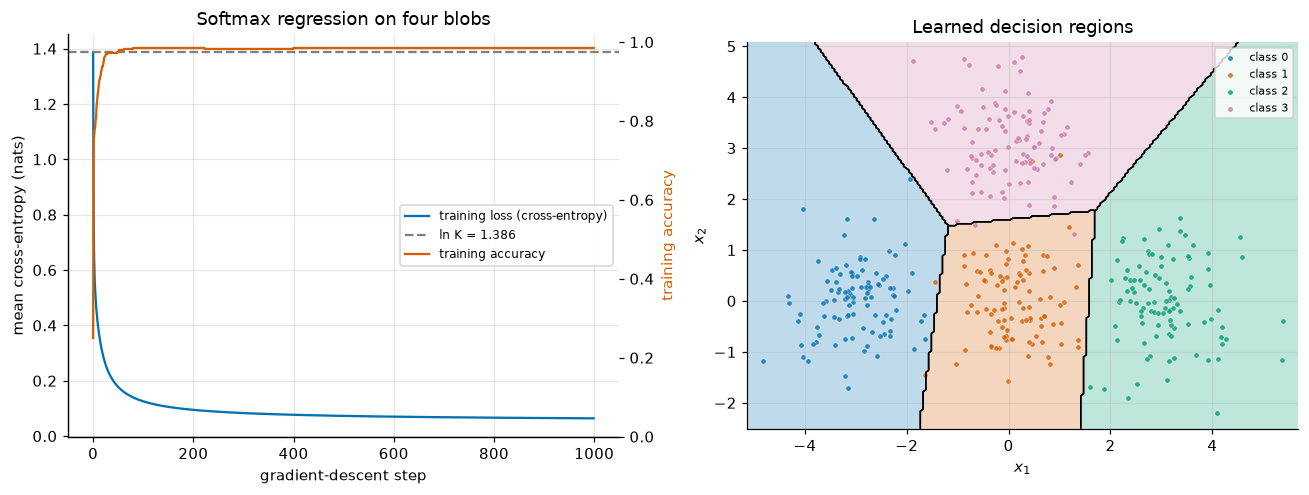

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ax = axes[0]
ax.plot(manual_losses, color=COLORS[0], label="training loss (cross-entropy)")
ax.axhline(math.log(K), color="gray", ls="--", label=f"ln K = {math.log(K):.3f}")
ax.set_xlabel("gradient-descent step")
ax.set_ylabel("mean cross-entropy (nats)")
ax.set_title("Softmax regression on four blobs")
ax2 = ax.twinx()
ax2.plot(manual_accs, color=COLORS[1], label="training accuracy")
ax2.set_ylabel("training accuracy", color=COLORS[1])
ax2.set_ylim(0, 1.02)
ax2.grid(False)
lines = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(lines, [l.get_label() for l in lines], loc="center right", fontsize=8)


def predict_model(points):
    """Predicted labels of the trained nn.Linear. points: (P, D) -> (P,)."""
    return model(points).argmax(dim=1)


plot_decision_boundary(predict_model, X, y, ax=axes[1], title="Learned decision regions")
axes[1].legend(loc="upper right", fontsize=7)
plt.tight_layout()
plt.show()

Left: the loss starts at $\ln 4$ and drops quickly, while the accuracy jumps from 25% to above 95% within the first few dozen steps; after that the loss keeps decreasing slowly as the model becomes more *confident*, with almost no change in accuracy. Right: four convex regions separated by straight lines, as Section 3 promised, close to the nearest-center regions but fitted to the data, so the middle region is not exactly symmetric.

### Accuracy and the confusion matrix

Accuracy is one number. A **confusion matrix** $C$ of shape `(K, K)` counts, for every pair of classes, how many examples of true class $t$ were predicted as class $p$: $C_{tp}$. The diagonal holds the correct predictions. A compact way to build it: the pair $(t, p)$ is encoded as the single integer $tK + p$ and counted with `torch.bincount`. (Notebook 25 covers evaluation in detail: precision, recall, imbalance.)

In [45]:
with torch.no_grad():
    pred = model(X).argmax(dim=1)                                  # (N,)
conf = torch.bincount(y * K + pred, minlength=K * K).reshape(K, K)  # (K, K): rows = true class, columns = predicted
print(f"training accuracy: {(pred == y).float().mean().item():.4f}\n")
print("confusion matrix (rows: true class, columns: predicted class)")
print("        " + "".join(f"pred {p:<3d}" for p in range(K)))
for t in range(K):
    print(f"true {t}  " + "".join(f"{conf[t, p].item():<8d}" for p in range(K)))
print("\nthe diagonal sums to", conf.diag().sum().item(), "of", N)

training accuracy: 0.9850

confusion matrix (rows: true class, columns: predicted class)
        pred 0  pred 1  pred 2  pred 3  
true 0  100     0       0       0       
true 1  2       96      0       2       
true 2  0       0       100     0       
true 3  0       2       0       98      

the diagonal sums to 394 of 400


Every mistake involves the middle class 1, which borders all three others: two class-1 points are predicted as class 0 and two as class 3, and two class-3 points fall into the middle region. Classes 0 and 2 are never confused with each other: their regions do not share a border.

### The limit of a linear classifier

Softmax regression can only produce convex regions with straight boundaries. Data whose classes are not arranged that way defeat it, however long we train. Three interleaved spiral arms:

In [46]:
X_sp, y_sp = make_spirals(classes=3, seed=0)                 # X_sp: (900, 2), y_sp: (900,)
K_sp = 3
model_sp = nn.Linear(2, K_sp)
with torch.no_grad():
    model_sp.weight.zero_()
    model_sp.bias.zero_()
optimizer_sp = torch.optim.SGD(model_sp.parameters(), lr=LR)
sp_losses = []
for step in range(STEPS):
    optimizer_sp.zero_grad()
    loss = F.cross_entropy(model_sp(X_sp), y_sp)
    loss.backward()
    optimizer_sp.step()
    sp_losses.append(loss.item())
with torch.no_grad():
    acc_sp = (model_sp(X_sp).argmax(dim=1) == y_sp).float().mean().item()
print(f"spirals: initial loss {sp_losses[0]:.4f} (ln 3 = {math.log(3):.4f}), final loss {sp_losses[-1]:.4f}, "
      f"training accuracy {acc_sp:.3f} (chance = {1 / K_sp:.3f})")

spirals: initial loss 1.0986 (ln 3 = 1.0986), final loss 1.0643, training accuracy 0.453 (chance = 0.333)


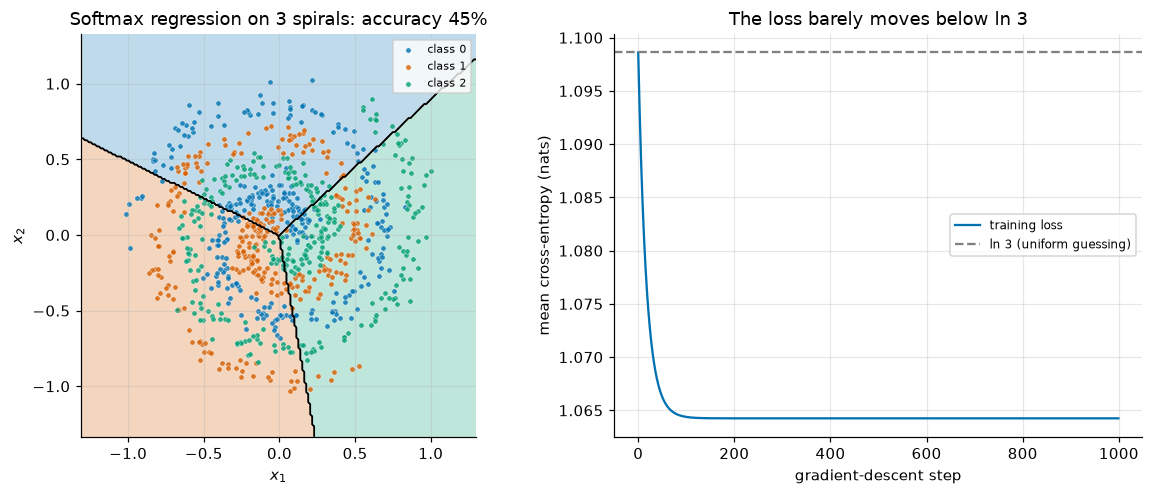

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
plot_decision_boundary(lambda pts: model_sp(pts).argmax(dim=1), X_sp, y_sp, ax=axes[0],
                       title=f"Softmax regression on 3 spirals: accuracy {acc_sp:.0%}")
axes[0].legend(loc="upper right", fontsize=7)
axes[1].plot(sp_losses, color=COLORS[0], label="training loss")
axes[1].axhline(math.log(3), color="gray", ls="--", label="ln 3 (uniform guessing)")
axes[1].set_xlabel("gradient-descent step")
axes[1].set_ylabel("mean cross-entropy (nats)")
axes[1].set_title("The loss barely moves below ln 3")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

The model has converged (the loss curve is flat), so this is not a matter of training longer: the best three convex wedges still cut every spiral arm into pieces, and the training accuracy is only about 45%, against 33% for guessing. The loss, about 1.06, has barely dropped below $\ln 3 \approx 1.10$, the loss of a model that knows nothing. Because the loss is convex, gradient descent has found the **best** linear classifier; the limit is the model, not the optimizer. Getting past it needs nonlinear decision regions — notebooks 11 and 12.

## Exercises

### Exercise 1 (modify): rescaling the logits of a trained model

The cell below takes the trained `model` from Section 7 and multiplies its weight **and** bias by a constant $c$, which multiplies every logit by $c$ (temperature $T = 1/c$). For each $c$ it reports the training accuracy, the cross-entropy, and the average confidence (the mean over examples of the largest predicted probability), and plots the loss and confidence against $c$.

1. Run it. Which of the three quantities change with $c$, and which do not? Explain why using the properties of softmax from Section 2.
2. Add $c = 0$ and $c = -1$ to `scales` and explain what you see.
3. Where is the loss smallest? Why might it not be exactly at $c = 1$? (Look at the left plot of Section 7.)

Answer in the markdown cell below.

<details>
<summary><b>💡 Hint</b></summary>

Multiplying all logits by $c > 0$ keeps their order, so the arg-max does not change. It does change the *gaps* between logits, and softmax probabilities depend on the gaps. For the third question: $c$ is one direction in parameter space; at the exact minimum of the loss, the derivative along every direction is zero.

</details>

c =  0.10:  accuracy 0.9850   loss 0.7548   mean confidence 0.4802
c =  0.25:  accuracy 0.9850   loss 0.3544   mean confidence 0.7198
c =  0.50:  accuracy 0.9850   loss 0.1411   mean confidence 0.8888
c =  1.00:  accuracy 0.9850   loss 0.0642   mean confidence 0.9675
c =  1.50:  accuracy 0.9850   loss 0.0597   mean confidence 0.9835
c =  2.00:  accuracy 0.9850   loss 0.0667   mean confidence 0.9892
c =  4.00:  accuracy 0.9850   loss 0.1134   mean confidence 0.9956
c =  8.00:  accuracy 0.9850   loss 0.2185   mean confidence 0.9983
smallest loss on the fine grid: 0.0590 at c = 1.33


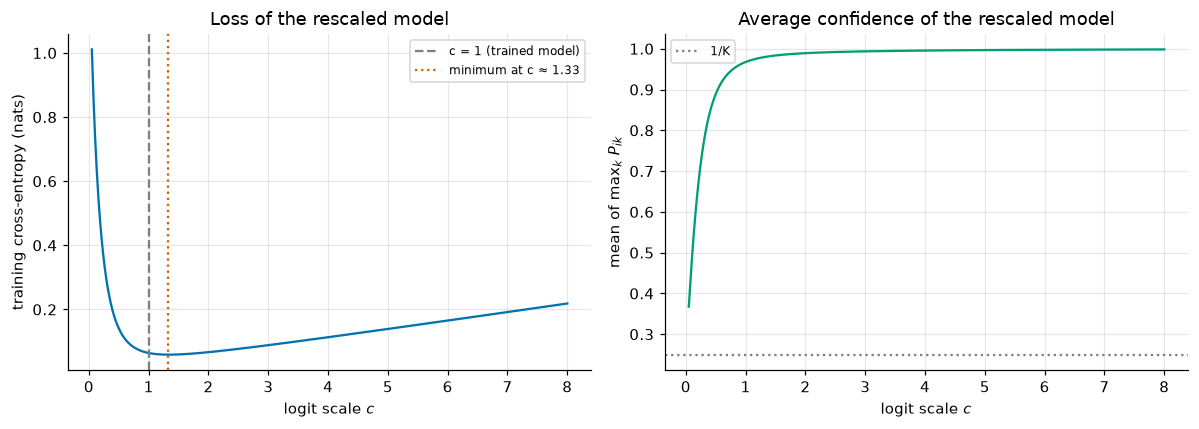

In [48]:
scales = [0.1, 0.25, 0.5, 1.0, 1.5, 2.0, 4.0, 8.0]
results = []
with torch.no_grad():
    Z_trained = model(X)                                    # (N, K) logits of the trained model
    for c in scales:
        Z_c = c * Z_trained                                 # same as multiplying W and b by c
        acc_c = (Z_c.argmax(dim=1) == y).float().mean().item()
        loss_c = F.cross_entropy(Z_c, y).item()
        conf_c = torch.softmax(Z_c, dim=1).max(dim=1).values.mean().item()
        results.append((c, acc_c, loss_c, conf_c))
        print(f"c = {c:5.2f}:  accuracy {acc_c:.4f}   loss {loss_c:.4f}   mean confidence {conf_c:.4f}")

    c_fine = torch.linspace(0.05, 8, 300)
    loss_fine = torch.tensor([F.cross_entropy(c * Z_trained, y).item() for c in c_fine.tolist()])
    conf_fine = torch.tensor([torch.softmax(c * Z_trained, dim=1).max(dim=1).values.mean().item() for c in c_fine.tolist()])
print(f"smallest loss on the fine grid: {loss_fine.min().item():.4f} at c = {c_fine[loss_fine.argmin()].item():.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(c_fine, loss_fine, color=COLORS[0])
ax1.axvline(1.0, color="gray", ls="--", label="c = 1 (trained model)")
ax1.axvline(c_fine[loss_fine.argmin()].item(), color=COLORS[1], ls=":", label=f"minimum at c ≈ {c_fine[loss_fine.argmin()].item():.2f}")
ax1.set_xlabel("logit scale $c$")
ax1.set_ylabel("training cross-entropy (nats)")
ax1.set_title("Loss of the rescaled model")
ax1.legend(fontsize=8)
ax2.plot(c_fine, conf_fine, color=COLORS[2])
ax2.axhline(1 / K, color="gray", ls=":", label="1/K")
ax2.set_xlabel("logit scale $c$")
ax2.set_ylabel("mean of max$_k$ $P_{ik}$")
ax2.set_title("Average confidence of the rescaled model")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

*Your answer:*

### Exercise 2 (implement): a stable softmax cross-entropy from scratch

Write `softmax_cross_entropy(logits, y)` for logits of shape `(N, K)` and integer labels of shape `(N,)`, returning the **mean** cross-entropy as a 0-d tensor. Requirements:

- Do not use `F.cross_entropy`, `F.log_softmax`, `F.nll_loss`, `torch.logsumexp`, or `torch.softmax`. Use the max-shift so it stays finite for logits of size 1000.
- Pick the correct-class entries by indexing.
- It must be differentiable with autograd. The check verifies that its gradient with respect to the logits is $(\operatorname{softmax}(Z) - Y)/N$.

<details>
<summary><b>💡 Hint</b></summary>

Row maxima: `m = logits.max(dim=1, keepdim=True).values` (shape `(N, 1)`). Stable log-probabilities: `logits - m - torch.log(torch.exp(logits - m).sum(dim=1, keepdim=True))`. Then `-log_probs[torch.arange(N), y].mean()`. Autograd handles the gradient through `max`, `exp`, `log` and indexing; the max-shift's contribution cancels exactly, as shift invariance requires.

</details>

In [ ]:
def softmax_cross_entropy(logits, y):
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
gen = torch.Generator().manual_seed(5)
Z_ex = 2 * torch.randn(64, 7, generator=gen)          # (64, 7)
y_ex = torch.randint(0, 7, (64,), generator=gen)      # (64,)
value = softmax_cross_entropy(Z_ex, y_ex)
check(isinstance(value, torch.Tensor) and value.dim() == 0, "softmax_cross_entropy should return a 0-d tensor (the mean loss)")
check_close(value, F.cross_entropy(Z_ex, y_ex), "loss on ordinary logits")
big = softmax_cross_entropy(1000 * Z_ex, y_ex)
check(bool(torch.isfinite(big)), f"loss for logits of size ~1000 is {big.item()}, should be finite")
check_close(big, F.cross_entropy(1000 * Z_ex, y_ex), "loss on logits × 1000", rtol=1e-5)
Z_req = Z_ex.clone().requires_grad_()
softmax_cross_entropy(Z_req, y_ex).backward()
check_close(Z_req.grad, (torch.softmax(Z_ex, dim=1) - F.one_hot(y_ex, 7).float()) / 64, "gradient w.r.t. logits")
Z_req_big = (1000 * Z_ex).requires_grad_()
softmax_cross_entropy(Z_req_big, y_ex).backward()
check(bool(torch.isfinite(Z_req_big.grad).all()), "gradient for logits of size ~1000 contains inf or nan")
passed("Exercise 2")

### Exercise 3 (debug): a classifier with two multiclass bugs

`train_and_predict` should train softmax regression from zero initialization with full-batch SGD (exactly like the `nn.Linear` run of Section 7) and return the model together with the predicted probabilities `P` (shape `(N, K)`, one distribution per **row**). The buggy version, in the comments, runs without error, the loss it reports goes down, and the accuracy is fine — but the model is not the one Section 7 trained, and `P` is not what it claims to be. There are **two** bugs. Fix both.

<details>
<summary><b>💡 Hint</b></summary>

Print `P.sum(dim=1)` and `P.sum(dim=0)` for the buggy version: which one is all ones? Then look at what `F.cross_entropy` receives — logits or probabilities? Section 5 derived the smallest value the buggy loss can ever reach.

</details>

In [ ]:
def train_and_predict(X, y, K, steps=STEPS, lr=LR):
    model = nn.Linear(X.shape[1], K)
    with torch.no_grad():
        model.weight.zero_()
        model.bias.zero_()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        # Buggy version:
        #     probs = torch.softmax(model(X), dim=1)
        #     loss = F.cross_entropy(probs, y)
        # YOUR CODE HERE
        raise NotImplementedError
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        # Buggy version:
        #     P = torch.softmax(model(X), dim=0)
        # YOUR CODE HERE
        raise NotImplementedError
    return model, P

In [ ]:
model_fixed, P_fixed = train_and_predict(X, y, K)
check_shape(P_fixed, (N, K), "P")
check_close(P_fixed.sum(dim=1), torch.ones(N), "row sums of P (each example's distribution over classes)", atol=1e-5)
check_close(model_fixed.weight.detach(), model.weight.detach(), "trained weight vs Section 7", rtol=1e-4, atol=1e-4)
check_close(model_fixed.bias.detach(), model.bias.detach(), "trained bias vs Section 7", rtol=1e-4, atol=1e-4)
passed("Exercise 3")

To see what the bugs do, here is the buggy function run directly next to the correct one:

In [53]:
def train_and_predict_buggy(X, y, K, steps=STEPS, lr=LR):
    model = nn.Linear(X.shape[1], K)
    with torch.no_grad():
        model.weight.zero_()
        model.bias.zero_()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    for _ in range(steps):
        optimizer.zero_grad()
        loss = F.cross_entropy(torch.softmax(model(X), dim=1), y)   # bug 1: double softmax
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        P = torch.softmax(model(X), dim=0)                          # bug 2: wrong dimension
    return model, P, loss.item()


model_bug, P_bug, reported = train_and_predict_buggy(X, y, K)
with torch.no_grad():
    for name, m_ in [("buggy", model_bug), ("correct (Section 7)", model)]:
        Z_ = m_(X)
        print(f"{name:20s} accuracy {(Z_.argmax(1) == y).float().mean().item():.4f}   "
              f"true cross-entropy {F.cross_entropy(Z_, y).item():.4f}   "
              f"mean confidence {torch.softmax(Z_, dim=1).max(dim=1).values.mean().item():.4f}")
print(f"loss reported by the buggy loop: {reported:.4f}   (lower bound log(1 + 3/e) = {math.log(1 + 3 / math.e):.4f})")
print("buggy P: row sums of the first 3 examples:", P_bug.sum(dim=1)[:3].tolist())
print("buggy P: column sums:", P_bug.sum(dim=0).tolist())
print("buggy P[0] =", P_bug[0].tolist())

buggy                accuracy 0.9875   true cross-entropy 0.0723   mean confidence 0.9652
correct (Section 7)  accuracy 0.9850   true cross-entropy 0.0642   mean confidence 0.9675
loss reported by the buggy loop: 0.7767   (lower bound log(1 + 3/e) = 0.7437)
buggy P: row sums of the first 3 examples: [0.013014153577387333, 0.003345884382724762, 0.001138489693403244]
buggy P: column sums: [1.0000004768371582, 0.9999999403953552, 0.9999998211860657, 0.9999998807907104]
buggy P[0] = [0.007747372146695852, 0.005266774445772171, 3.2225342008510255e-17, 6.546964304021685e-09]


### Exercise 4 (investigate): the initial loss as a debugging tool

Section 4 claimed that a healthy classifier starts at $L \approx \ln K$. Here we test what a *different* initial loss reveals. The scaffold trains softmax regression on the blobs from three initializations:

- **small:** weights $\sim \mathcal{N}(0, 0.01^2)$, zero bias — the healthy case;
- **huge weights:** weights $\sim \mathcal{N}(0, 10^2)$ — as if the initialization scale, or the input scale, were off by a factor of 1000;
- **biased:** small weights, but the bias of class 0 set to $+8$ — as if the model started out convinced that everything is class 0.

It prints the initial loss next to $\ln K$ and plots the loss curves. Run it, then answer in the markdown cell:

1. Explain each initial loss quantitatively. (For the biased case, work out $P_{i0}$ and the loss of the class-0 and of the other examples.)
2. How many steps does each run need to get below, say, loss 0.2? Why does the huge-weight run waste so many steps, even though the loss is convex?
3. In one or two sentences: what does an initial loss far *above* $\ln K$ tell you, and what would an initial loss far *below* $\ln K$ tell you?

Optionally add a fourth run whose *inputs* are multiplied by 100 instead.

<details>
<summary><b>💡 Hint</b></summary>

With huge weights the logits are in the tens, so most examples are confidently assigned to *some* class — usually the wrong one — and each wrong example costs about the gap between its largest logit and its true-class logit. For the bias: $P_{i0} \approx e^8/(e^8 + 3)$. For the "far below" question: distinguish nearly uniform logits from random logits that happen to align with the labels. How much evidence does one initialization provide?

</details>

small              initial loss    1.389  (ln K = 1.386)   steps to loss < 0.2: 41   final loss 0.0642


huge weights       initial loss   19.680  (ln K = 1.386)   steps to loss < 0.2: 101   final loss 0.0658


biased to class 0  initial loss    6.007  (ln K = 1.386)   steps to loss < 0.2: 46   final loss 0.0645


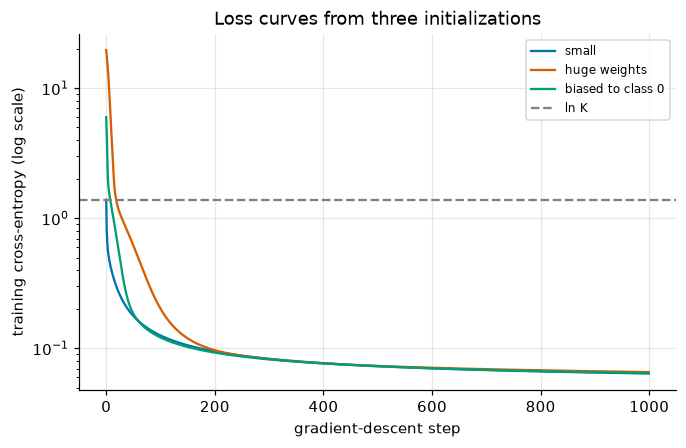

In [54]:
def init_small(m):
    with torch.no_grad():
        m.weight.normal_(0, 0.01)
        m.bias.zero_()


def init_huge(m):
    with torch.no_grad():
        m.weight.normal_(0, 10.0)
        m.bias.zero_()


def init_biased(m):
    init_small(m)
    with torch.no_grad():
        m.bias[0] = 8.0


curves = {}
for name, init in [("small", init_small), ("huge weights", init_huge), ("biased to class 0", init_biased)]:
    torch.manual_seed(0)
    m = nn.Linear(D, K)
    init(m)
    opt = torch.optim.SGD(m.parameters(), lr=LR)
    hist = []
    for step in range(STEPS):
        opt.zero_grad()
        loss = F.cross_entropy(m(X), y)
        hist.append(loss.item())
        loss.backward()
        opt.step()
    curves[name] = hist
    below = next((t for t, v in enumerate(hist) if v < 0.2), None)
    print(f"{name:18s} initial loss {hist[0]:8.3f}  (ln K = {math.log(K):.3f})   "
          f"steps to loss < 0.2: {below}   final loss {hist[-1]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
for k, (name, hist) in enumerate(curves.items()):
    ax.semilogy(hist, color=COLORS[k], label=name)
ax.axhline(math.log(K), color="gray", ls="--", label="ln K")
ax.set_xlabel("gradient-descent step")
ax.set_ylabel("training cross-entropy (log scale)")
ax.set_title("Loss curves from three initializations")
ax.legend(fontsize=8)
plt.show()

*Your conclusion:*

## Summary and what's next

- **One-vs-rest** with $K$ independent binary classifiers gives scores that do not sum to 1, regions claimed by no class or by several, and can fail outright for a class that sits between others.
- **Softmax** turns $K$ logits into a distribution: $p_k = e^{z_k}/\sum_j e^{z_j}$. It is positive, sums to 1, ignores a common shift of the logits, and preserves their order; the temperature (scale) of the logits moves it between the arg-max and the uniform distribution. For $K = 2$ it is $\sigma(z_1 - z_0)$: logistic regression is the special case.
- **Softmax regression** $P = \operatorname{softmax}(XW^\top + \mathbf{b})$ predicts $\arg\max_k Z_{ik}$; its decision regions are convex polygons bounded by the lines $(\mathbf{w}_j - \mathbf{w}_k)\cdot\mathbf{x} + (b_j - b_k) = 0$.
- The loss is **categorical cross-entropy**, the average negative log-probability of the correct class, $-\frac1N\sum_i \log P_{i, y_i}$ — maximum likelihood for a categorical model. At a small initialization it is $\approx \ln K$: check this before training.
- Compute it **stably** with log-softmax $z_k - \operatorname{lse}(\mathbf{z})$ and the max-shift. In PyTorch: `F.cross_entropy(logits, integer_labels)` — logits, not probabilities (double softmax is a silent bug), and softmax over the class dimension.
- The gradient with respect to the logits is $(P - Y)/N$, and $\nabla_W L = \frac1N(P - Y)^\top X$. The loss is convex, with flat directions coming from shift invariance.

What remains: every linear classifier, binary or multiclass, carves the input space into convex regions with straight boundaries. XOR (notebook 08), concentric rings, and the spirals above defeat it, no matter how it is trained. Notebook 11 combines several linear units — perceptrons feeding into perceptrons — to build regions that are not convex, and notebook 12 asks how far that idea can go.